In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
from sklearn.ensemble import RandomForestClassifier

In [3]:
df = pd.read_csv("../data/water_potability.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [5]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [8]:
model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [9]:
y_pred = model.predict(X_test)

In [10]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("\nRandom Forest Evaluation")
print("------------------------")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


Random Forest Evaluation
------------------------
Accuracy : 0.663109756097561
Precision: 0.6446280991735537
Recall   : 0.3046875
F1 Score : 0.41379310344827586


In [11]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.89      0.76       400
           1       0.64      0.30      0.41       256

    accuracy                           0.66       656
   macro avg       0.66      0.60      0.59       656
weighted avg       0.66      0.66      0.63       656



In [12]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[357  43]
 [178  78]]


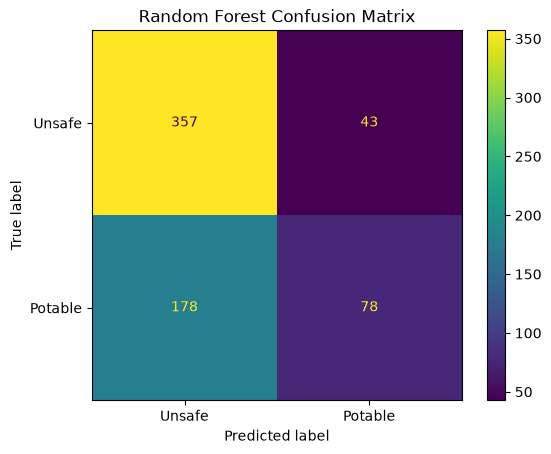

In [13]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Unsafe", "Potable"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")

plt.show()

In [14]:
forest_model = model.named_steps["classifier"]

In [15]:
importance = forest_model.feature_importances_

In [16]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance)


Feature Importance:
           Feature  Importance
0               ph    0.129452
4          Sulfate    0.128327
1         Hardness    0.121530
3      Chloramines    0.115588
2           Solids    0.112325
8        Turbidity    0.100219
5     Conductivity    0.099791
6   Organic_carbon    0.096651
7  Trihalomethanes    0.096117


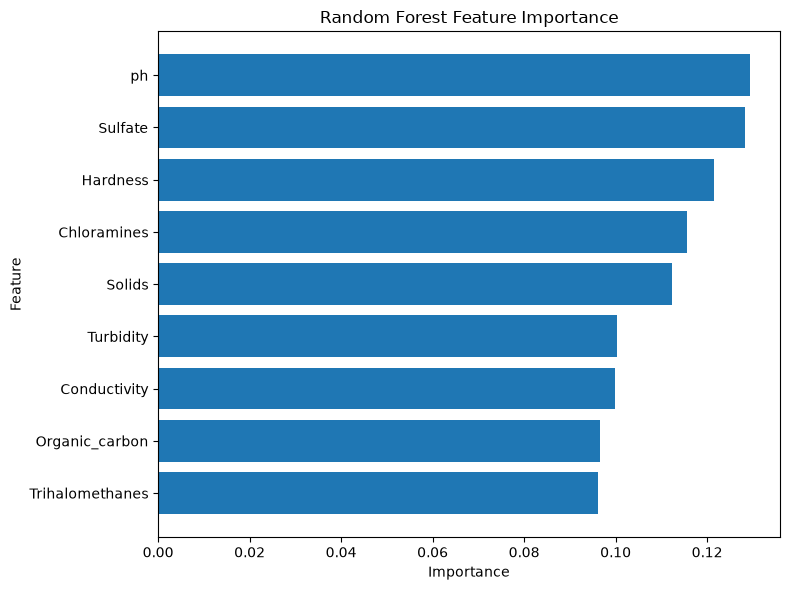

In [17]:
plt.figure(figsize=(8, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [18]:
probabilities = model.predict_proba(X_test)

print("\nFirst 5 prediction probabilities:")
print(probabilities[:5])


First 5 prediction probabilities:
[[0.74 0.26]
 [0.74 0.26]
 [0.73 0.27]
 [0.62 0.38]
 [0.75 0.25]]


In [19]:
for n in [10, 50, 100, 200]:

    rf = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("classifier", RandomForestClassifier(
            n_estimators=n,
            random_state=42
        ))
    ])

    rf.fit(X_train, y_train)

    prediction = rf.predict(X_test)

    score = accuracy_score(
        y_test,
        prediction
    )

    print(
        f"Trees: {n} | "
        f"Accuracy: {score:.4f}"
    )

Trees: 10 | Accuracy: 0.6524
Trees: 50 | Accuracy: 0.6555
Trees: 100 | Accuracy: 0.6631
Trees: 200 | Accuracy: 0.6677
